### Check distributions of number of active pixels

From Pereira et al. Landat fire mask dataset:


Auditing Dataset Source: NA1 (North America Split 1)
Extracting sample chunk: 150 of 732 sub-archives...
Isolated 744 target mask files for metrics profiling.

Distribution Profiling Summary for NA1 (North America Split 1):
  Total masks evaluated: 744
  Empty patches (0 px):   0 (0.0%)
  Sparse patches (1-5 px): 644
  Dense fire (>200 px):    4
  Descriptive Stats (Min/Med/Mean/Max): 1 / 2.0 / 6.1 / 390

Auditing Dataset Source: NA2 (North America Split 2)
Extracting sample chunk: 150 of 450 sub-archives...
Isolated 76 target mask files for metrics profiling.

Distribution Profiling Summary for NA2 (North America Split 2):
  Total masks evaluated: 76
  Empty patches (0 px):   0 (0.0%)
  Sparse patches (1-5 px): 64
  Dense fire (>200 px):    0
  Descriptive Stats (Min/Med/Mean/Max): 1 / 2.0 / 5.1 / 96

Auditing Dataset Source: SA (South America)
Extracting sample chunk: 150 of 594 sub-archives...
Isolated 804 target mask files for metrics profiling.

Distribution Profiling Summary for

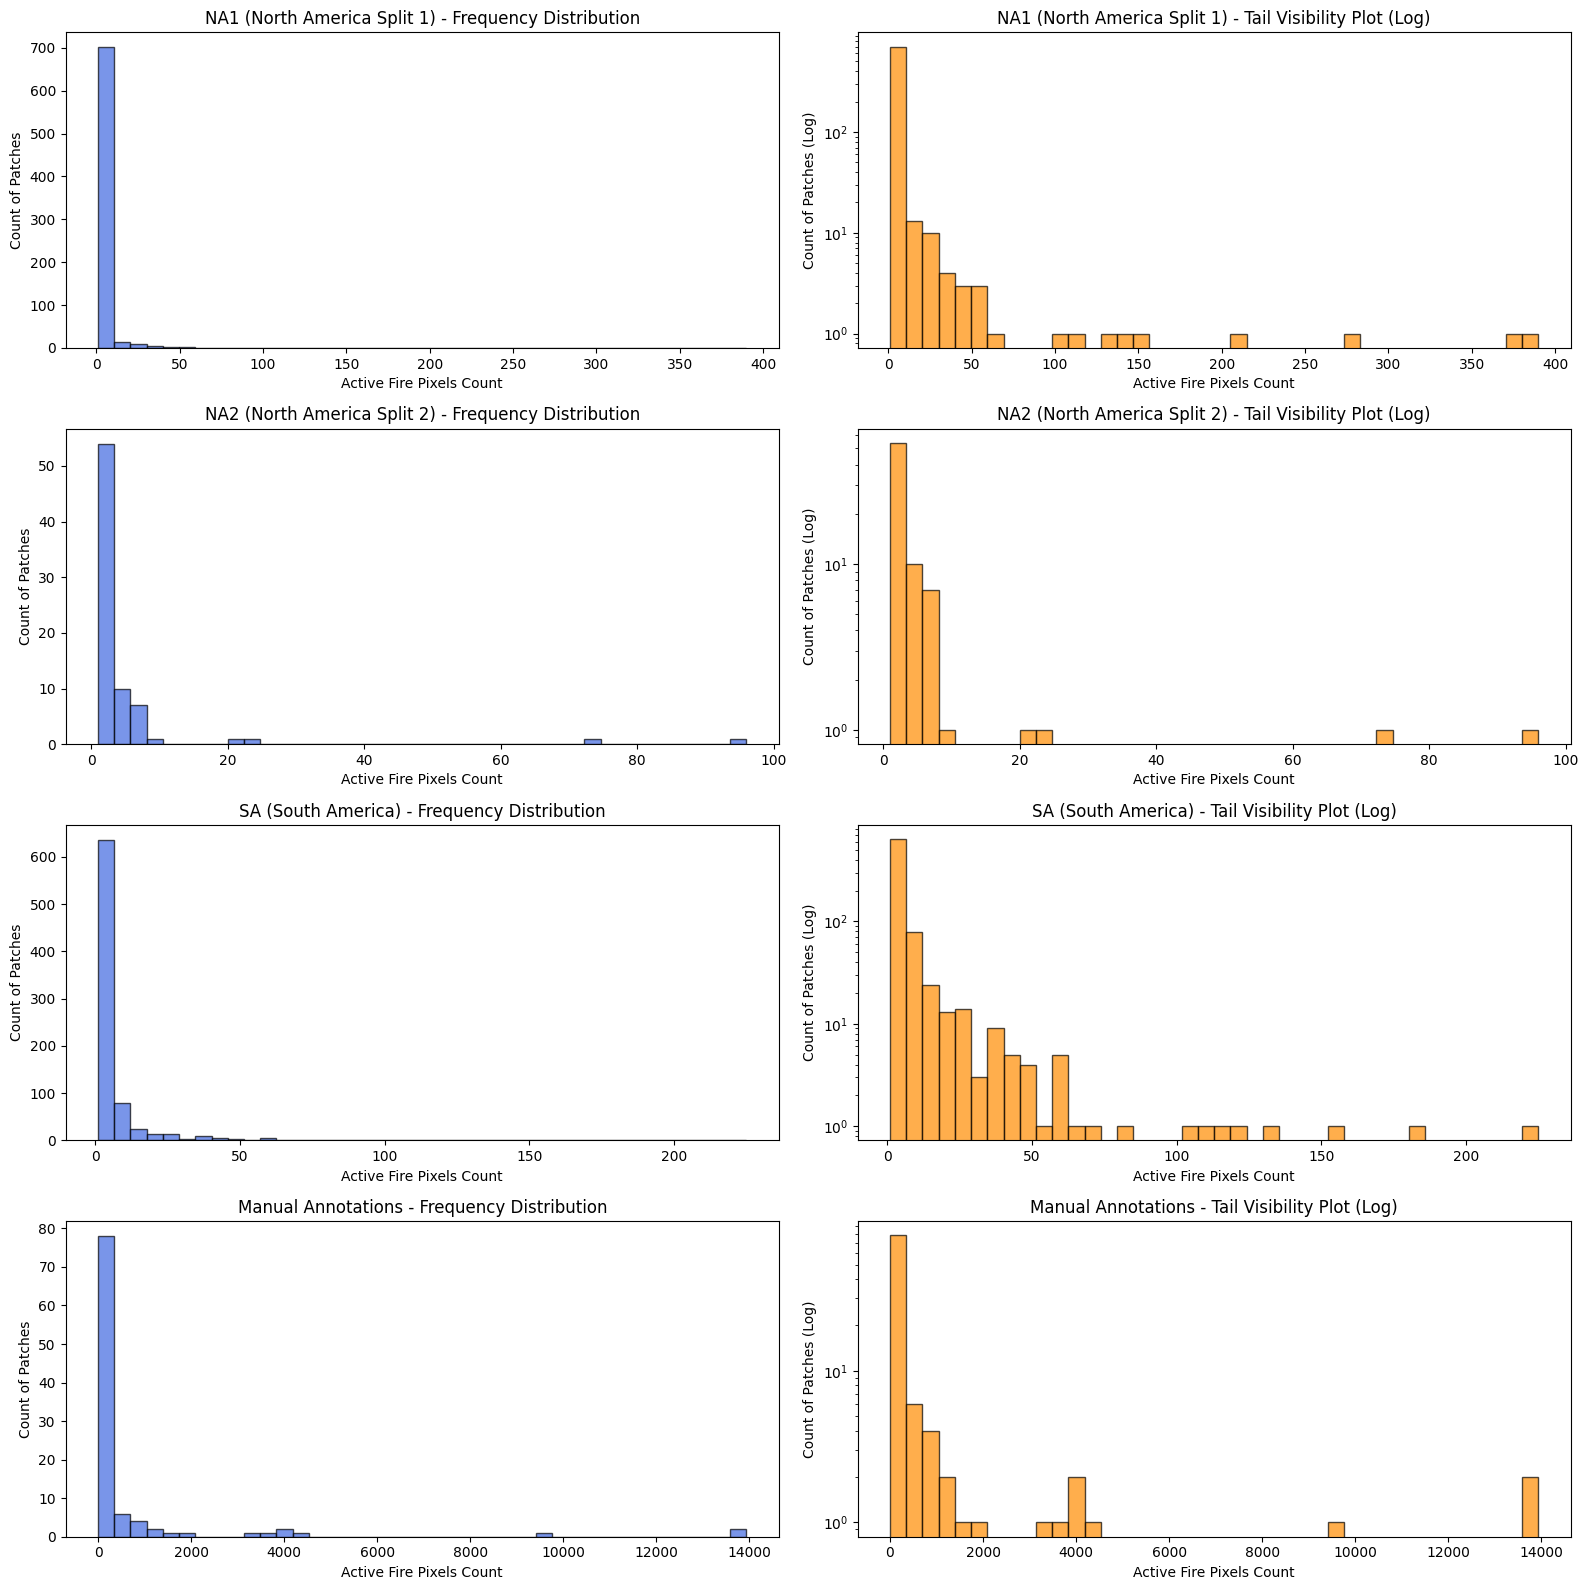

In [1]:
import os
import io
import re
import glob
import zipfile
import gdown
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

DATASET_CONFIGS = {
    "NA1 (North America Split 1)": {
        "drive_id": "1BXRGldTdGGNeWDOFqNnmiNPuPQjweB2M", 
        "is_flat": False,
        "mask_pattern": "*intersection*.tif"
    },
    "NA2 (North America Split 2)": {
        "drive_id": "1zW_pEIggJ5Li7uQX9XKMfHkcgL3kiUoi",
        "is_flat": False,
        "mask_pattern": "*intersection*.tif"
    },
    "SA (South America)": {
        "drive_id": "1hnBUmYkvFYohTf9hTnKiyp2MXVevglK7",
        "is_flat": False,
        "mask_pattern": "*intersection*.tif"
    },
    "Manual Annotations": {
        "drive_id": "1LdsX-rH5hy_82jfc1akO8p4n0_N8lRgf",
        "is_flat": True,
        "mask_pattern": "*.tif*"
    }
}

# Execution parameters
MAX_SUB_ARCHIVES_TO_SAMPLE = 150  # Keep sampling uniform across nested datasets
BASE_TMP_DIR = "/tmp/dataset_audit"
os.makedirs(BASE_TMP_DIR, exist_ok=True)

all_results = {}

for name, cfg in DATASET_CONFIGS.items():
    print(f"\n{'='*60}\nAuditing Dataset Source: {name}\n{'='*60}")
    
    zip_path = os.path.join(BASE_TMP_DIR, f"{re.sub(r'[^a-zA-Z0-9]', '_', name)}.zip")
    extract_dir = os.path.join(BASE_TMP_DIR, f"{re.sub(r'[^a-zA-Z0-9]', '_', name)}_extracted")
    os.makedirs(extract_dir, exist_ok=True)
    
    # 1. Download source from Google Drive if not locally cached
    if not os.path.exists(zip_path):
        print(f"Downloading source archive from Google Drive...")
        try:
            gdown.download(id=cfg['drive_id'], output=zip_path, quiet=False)
        except Exception as e:
            print(f"Skipping {name}: Download failed ({e})")
            continue

    active_counts = []
    
    # 2. Extract contents based on archive structure topology
    with zipfile.ZipFile(zip_path, 'r') as parent:
        if not cfg['is_flat']:
            # Nested structure parsing
            nested_zips = [f for f in parent.namelist() if f.endswith('.zip') and 'masks' in f.lower()]
            sample_size = min(len(nested_zips), MAX_SUB_ARCHIVES_TO_SAMPLE)
            print(f"Extracting sample chunk: {sample_size} of {len(nested_zips)} sub-archives...")
            
            for n_name in nested_zips[:sample_size]:
                with parent.open(n_name) as n_file:
                    with zipfile.ZipFile(io.BytesIO(n_file.read())) as child:
                        child.extractall(extract_dir)
        else:
            # Flat archive parsing
            print(f"Flat archive detected. Unpacking target GeoTIFF arrays...")
            parent.extractall(extract_dir)
            
    # 3. Locate target files matching mask rules
    tif_paths = glob.glob(os.path.join(extract_dir, "**", cfg['mask_pattern']), recursive=True)
    total_masks = len(tif_paths)
    print(f"Isolated {total_masks} target mask files for metrics profiling.")
    
    if total_masks == 0:
        print(f"No matching files found for pattern: {cfg['mask_pattern']}")
        continue

    # 4. Profile pixel matrices
    for path in tif_paths:
        try:
            with rasterio.open(path) as src:
                mask = src.read(1)
            # Count pixels matching the active fire condition
            active_counts.append(int(np.sum(mask == 1)))
        except Exception as e:
            print(f"Warning: Corrupted image file skipped: {path} -> {e}")

    active_counts = np.array(active_counts)
    all_results[name] = active_counts
    
    # 5. Output localized text summary metrics
    print(f"\nDistribution Profiling Summary for {name}:")
    print(f"  Total masks evaluated: {len(active_counts)}")
    print(f"  Empty patches (0 px):   {(active_counts == 0).sum()} ({(active_counts == 0).sum()/len(active_counts)*100:.1f}%)")
    print(f"  Sparse patches (1-5 px): {((active_counts >= 1) & (active_counts <= 5)).sum()}")
    print(f"  Dense fire (>200 px):    {(active_counts > 200).sum()}")
    print(f"  Descriptive Stats (Min/Med/Mean/Max): {active_counts.min()} / {np.median(active_counts):.1f} / {active_counts.mean():.1f} / {active_counts.max()}")

# 6. Global Comparative Visualization
if all_results:
    fig, axes = plt.subplots(len(all_results), 2, figsize=(16, 4 * len(all_results)))
    if len(all_results) == 1:
        axes = np.expand_dims(axes, axis=0) # Normalize layout tracking array dimensions
        
    for idx, (name, counts) in enumerate(all_results.items()):
        # Standard Linear Histogram
        axes[idx, 0].hist(counts, bins=40, color='royalblue', edgecolor='black', alpha=0.7)
        axes[idx, 0].set_title(f"{name} - Frequency Distribution")
        axes[idx, 0].set_xlabel("Active Fire Pixels Count")
        axes[idx, 0].set_ylabel("Count of Patches")
        
        # Log Scale Tail Histogram
        axes[idx, 1].hist(counts[counts > 0], bins=40, color='darkorange', edgecolor='black', alpha=0.7)
        axes[idx, 1].set_yscale('log')
        axes[idx, 1].set_title(f"{name} - Tail Visibility Plot (Log)")
        axes[idx, 1].set_xlabel("Active Fire Pixels Count")
        axes[idx, 1].set_ylabel("Count of Patches (Log)")
        
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_TMP_DIR, "dataset_comparative_distributions.png"), dpi=150)
    plt.show()

### Check how many masks are contained

In [4]:
import io
import gdown
import zipfile

def count_total_masks_instant(file_source, is_flat=False):
    """
    Scans zip central directory metadata from an in-memory BytesIO buffer 
    to instantly calculate absolute mask volumes.
    """
    total_mask_count = 0
    with zipfile.ZipFile(file_source, 'r') as parent:
        if is_flat:
            total_mask_count = sum(1 for f in parent.namelist() if f.lower().endswith(('.tif', '.tiff')))
        else:
            nested_zips = [f for f in parent.namelist() if f.endswith('.zip') and 'masks' in f.lower()]
            print(f"Analyzing internal metadata for {len(nested_zips)} sub-archives...")
            for n_name in nested_zips:
                with parent.open(n_name) as n_file:
                    with zipfile.ZipFile(io.BytesIO(n_file.read())) as child:
                        total_mask_count += sum(1 for f in child.namelist() if 'intersection' in f.lower() and f.endswith('.tif'))
    return total_mask_count

# Run the mask volume quantification check
print(f"{'='*60}\nEstimating Complete Operational Workload\n{'='*60}")
for name, cfg in DATASET_CONFIGS.items():
    print(f"\nStreaming index metadata for {name}...")
    try:
        meta_buffer = io.BytesIO()
        # Fixed: using id instead of url, removed remaining_ok
        gdown.download(id=cfg['drive_id'], output=meta_buffer, quiet=True)
        meta_buffer.seek(0)
        
        absolute_total = count_total_masks_instant(meta_buffer, is_flat=cfg['is_flat'])
        print(f"  --> Full Remote Archive contains: {absolute_total:,} target GeoTIFF masks.")
    except Exception as e:
        print(f"  --> Metadata parsing failed: {e}")

Estimating Complete Operational Workload

Streaming index metadata for NA1 (North America Split 1)...
Analyzing internal metadata for 732 sub-archives...
  --> Full Remote Archive contains: 3,764 target GeoTIFF masks.

Streaming index metadata for NA2 (North America Split 2)...
Analyzing internal metadata for 450 sub-archives...
  --> Full Remote Archive contains: 452 target GeoTIFF masks.

Streaming index metadata for SA (South America)...
Analyzing internal metadata for 594 sub-archives...
  --> Full Remote Archive contains: 5,696 target GeoTIFF masks.

Streaming index metadata for Manual Annotations...
  --> Full Remote Archive contains: 100 target GeoTIFF masks.


Total: 10,012

Assuming 80% of data will be filtered after filtering for >= 10 active pixels, we will get roughly 2,000 target masks.